# 1.3 · Redes neuronales profundas

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MaxRobles1/deep-learning-equation-to-code/blob/main/topics/01-introduction/1.3-deep-neural-networks.ipynb)

**Objetivos.** Al terminar esta lección podrás:
1. Escribir una red de cualquier profundidad como una sucesión de capas.
2. Explicar qué dice, y qué no dice, el teorema de aproximación universal.
3. Demostrar con un experimento por qué la profundidad permite representar funciones
   complejas con muchas menos neuronas.
4. Construir redes profundas en NumPy y en PyTorch, y comprobar que dan el mismo resultado.

**Prerrequisitos.** Lección 1.2 (neuronas, capas y ReLU).

Preparamos el entorno: bibliotecas, semillas y formato de impresión.

In [1]:
import os
from itertools import pairwise

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

QUICK_MODE = os.environ.get("QUICK_MODE") == "1"  # set by CI; this lesson is fast either way
SEED = 0
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.dpi"] = 90

## 1 · Intuición

### Poco profunda o profunda

En la lección 1.2 construimos una red con **una** capa oculta. A esa forma se le llama red
**poco profunda** (*shallow*). Una red **profunda** (*deep*) tiene **dos o más** capas ocultas
encadenadas: la salida de cada una es la entrada de la siguiente. La figura 1 compara las dos
formas.

Dos palabras nos van a acompañar:
- **Profundidad:** cuántas capas tiene la red.
- **Anchura:** cuántas neuronas tiene cada capa.

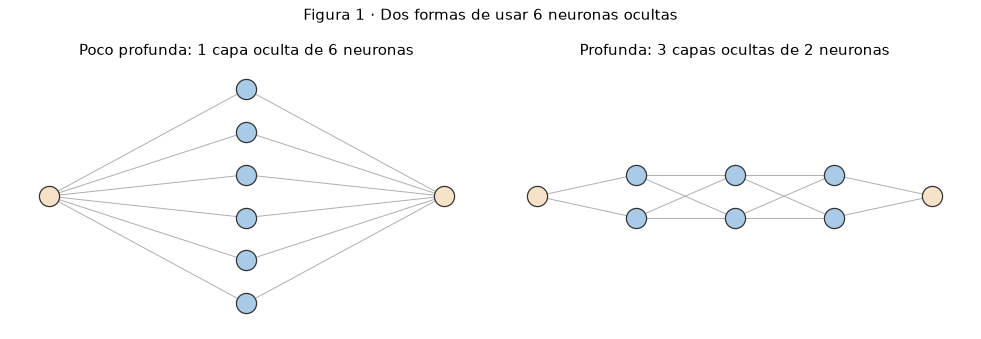

In [2]:
def draw_network(ax, sizes: list[int], title: str) -> None:
    """Draw a fully connected network as columns of circles joined by lines."""
    xs = np.linspace(0, 1, len(sizes))
    positions = [np.linspace(0.5 - 0.08 * (n - 1), 0.5 + 0.08 * (n - 1), n) for n in sizes]
    for (x0, ys0), (x1, ys1) in pairwise(zip(xs, positions, strict=True)):
        for y0 in ys0:
            for y1 in ys1:
                ax.plot([x0, x1], [y0, y1], color="#b0b0b0", linewidth=0.8, zorder=1)
    for i, (x, ys) in enumerate(zip(xs, positions, strict=True)):
        color = "#f6e3c7" if i in (0, len(sizes) - 1) else "#a9cbe8"
        ax.scatter([x] * len(ys), ys, s=260, color=color, edgecolor="#333333", zorder=2)
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.axis("off")


fig, (ax_shallow, ax_deep) = plt.subplots(1, 2, figsize=(11, 3.8))
draw_network(ax_shallow, [1, 6, 1], "Poco profunda: 1 capa oculta de 6 neuronas")
draw_network(ax_deep, [1, 2, 2, 2, 1], "Profunda: 3 capas ocultas de 2 neuronas")
fig.suptitle("Figura 1 · Dos formas de usar 6 neuronas ocultas")
fig.tight_layout()
plt.show()

### Doblar el papel

Una buena forma de imaginar una capa con ReLU es pensar en **doblar una hoja de papel**. Cada
doblez hace que regiones distintas de la entrada terminen una encima de otra. Si después
doblas la hoja ya doblada, cada pliegue anterior se vuelve a doblar: los pliegues **se
multiplican**. Con pocos dobleces sucesivos se obtienen formas muy complicadas. Eso hace una
red profunda: cada capa trabaja sobre lo que ya transformó la anterior.

### La aparente paradoja

Existe un resultado famoso, el **teorema de aproximación universal**: una red con **una sola**
capa oculta puede aproximar tanto como queramos casi cualquier función. Entonces, ¿para qué
la profundidad? La trampa está en un detalle que el teorema no dice: **cuántas neuronas hacen
falta**. En esta lección construimos una función que una red profunda dibuja con 20 neuronas
y una red de una sola capa necesita más de mil.

## 2 · Matemática

Usamos la notación del curso ([docs/NOTATION.md](../../docs/NOTATION.md)). Después de cada
fórmula explicamos qué significa cada símbolo, qué hace la fórmula y para qué se usa.

### 2.1 Una red profunda es una sucesión de capas

$$\mathbf{a}^{[0]} = \mathbf{x}, \qquad
\mathbf{z}^{[l]} = \mathbf{W}^{[l]}\mathbf{a}^{[l-1]} + \mathbf{b}^{[l]}, \qquad
\mathbf{a}^{[l]} = g^{[l]}\big(\mathbf{z}^{[l]}\big), \qquad l = 1, \dots, L$$

**Donde:**
- $\mathbf{x}$ es la entrada, que hace las veces de "activación cero", $\mathbf{a}^{[0]}$.
- $L$ es el número de capas con pesos; la red tiene $L - 1$ capas ocultas.
- $\mathbf{W}^{[l]}$ y $\mathbf{b}^{[l]}$ son los pesos y los sesgos de la capa $l$.
- $g^{[l]}$ es la activación de la capa $l$: ReLU en las capas ocultas y, en esta lección,
  ninguna (la identidad) en la capa de salida.
- $\mathbf{a}^{[L]}$ es la salida de la red, la predicción $\hat{y}$.

**Qué hace:** aplica la misma operación de la lección 1.2 una capa tras otra: cada capa toma
las activaciones de la anterior y produce las suyas.

**Para qué se usa:** describe cualquier red totalmente conectada, sin importar cuántas capas
tenga. En código se convierte en un ciclo sobre las capas, como la función `forward` de la
sección 3.

### 2.2 El teorema de aproximación universal (versión informal)

Para toda función continua $f$ en una región acotada y todo margen de error $\varepsilon > 0$,
existen un número de neuronas $N$ y parámetros tales que

$$F(\mathbf{x}) = \sum_{i=1}^{N} v_i\, g\big(\mathbf{w}_i^\top\mathbf{x} + b_i\big)
\quad \text{cumple} \quad \big|F(\mathbf{x}) - f(\mathbf{x})\big| < \varepsilon
\ \text{ para toda } \mathbf{x} \text{ de la región.}$$

**Donde:**
- $f$ es la función que queremos aproximar.
- $F$ es una red con **una** capa oculta de $N$ neuronas.
- $\mathbf{w}_i$ y $b_i$ son los pesos y el sesgo de la neurona oculta $i$, y $v_i$ su peso en
  la salida.
- $g$ es una activación no lineal adecuada, como la sigmoide (Cybenko, 1989) o ReLU.
- $\varepsilon$ es el error máximo que estamos dispuestos a aceptar.

**Qué hace:** garantiza que, con suficientes neuronas, una sola capa oculta puede acercarse
tanto como queramos a cualquier función continua.

**Para qué se usa:** justifica que las redes neuronales son lo bastante flexibles para
representar casi cualquier relación entre entradas y salidas.

**Lo que no dice:** cuántas neuronas hacen falta (pueden ser muchísimas) ni cómo encontrar
los parámetros a partir de datos. Esas dos preguntas son las que hacen importante a la
profundidad y al entrenamiento.

### 2.3 Una "tienda de campaña" hecha con dos ReLU

$$t(x) = 2\,\mathrm{ReLU}(x) - 4\,\mathrm{ReLU}(x - 0.5) =
\begin{cases} 2x & \text{si } 0 \le x \le 0.5 \\ 2 - 2x & \text{si } 0.5 < x \le 1 \end{cases}$$

**Donde:** $x$ es un número entre 0 y 1, y cada $\mathrm{ReLU}$ es una neurona oculta: la
primera se activa desde $x = 0$ y la segunda desde $x = 0.5$.

**Qué hace:** sube en línea recta de 0 a 1 y vuelve a bajar a 0, como el perfil de una tienda
de campaña. Lleva el intervalo $[0, 1]$ sobre sí mismo **dos veces**: una al subir y otra al
bajar.

**Para qué se usa:** es la pieza con la que construiremos la red profunda. Con solo dos
neuronas produce un "doblez".

### 2.4 Componer la tienda: una sierra

$$t^{(k)}(x) = \underbrace{t\big(t(\cdots t(x)\cdots)\big)}_{k \text{ veces}}$$

**Donde:** $k$ es el número de veces que aplicamos $t$, que en la red es el número de capas
ocultas.

**Qué hace:** cada nueva aplicación de $t$ recorre dos veces cada tramo recto que ya existía,
así que **duplica** el número de tramos. Después de $k$ capas, $t^{(k)}$ es una sierra con
$2^k$ tramos rectos, usando solo $2k$ neuronas ocultas.

**Para qué se usa:** es el ejemplo clásico de Telgarsky (2016) para mostrar el poder de la
profundidad: el número de tramos crece **exponencialmente** con las capas.

### 2.5 Lo que puede dibujar una sola capa

Con una entrada $x$ de una dimensión, una red de una capa oculta con $N$ neuronas ReLU es

$$F(x) = \sum_{i=1}^{N} v_i\, \mathrm{ReLU}(w_i x + b_i) + c$$

**Donde:** $w_i$, $b_i$ y $v_i$ son los parámetros de la neurona $i$, y $c$ el sesgo de la
salida.

**Qué hace:** suma $N$ funciones ReLU. Cada una aporta, como máximo, **un quiebre** a la
curva, así que $F$ tiene a lo más $N + 1$ tramos rectos.

**Para qué se usa:** nos dice cuántas neuronas necesita una red poco profunda para copiar la
sierra: para $2^k$ tramos hacen falta $2^k - 1$ quiebres, es decir, **al menos $2^k - 1$
neuronas**. Una red profunda lo logra con $2k$. Para $k = 10$: 20 neuronas contra más de 1,000.

## 3 · Desde cero (NumPy)

### 3.1 Una red de cualquier profundidad

La función `forward` es la fórmula de la sección 2.1 convertida en un ciclo.

In [3]:
def relu(z: np.ndarray) -> np.ndarray:
    """Rectified linear unit: max(0, z)."""
    return np.maximum(0.0, z)


def identity(z: np.ndarray) -> np.ndarray:
    """No activation: used in the output layer."""
    return z


def forward(x: np.ndarray, layers: list) -> np.ndarray:
    """Run a fully connected network of any depth. Rows of x are examples.

    Each layer is a tuple (W, b, activation) and computes activation(a @ W.T + b).
    """
    a = x
    for W, b, activation in layers:
        a = activation(a @ W.T + b)
    return a


def count_params(layer_sizes: list[int]) -> int:
    """Number of weights and biases of a fully connected network."""
    return sum(n_out * (n_in + 1) for n_in, n_out in pairwise(layer_sizes))

### 3.2 La red-sierra profunda

La primera capa oculta calcula las dos ReLU de la tienda. Cada capa oculta siguiente vuelve
a aplicar la tienda a la salida de la anterior, y la capa de salida combina las dos neuronas
de la última capa como $2h_1 - 4h_2$.

In [4]:
def sawtooth_layers(depth: int) -> list:
    """Deep ReLU network that composes the tent map `depth` times (2 neurons per hidden layer)."""
    first = (np.array([[1.0], [1.0]]), np.array([0.0, -0.5]), relu)
    # Each hidden layer applies the tent map to the previous output 2*h1 - 4*h2.
    hidden = (np.array([[2.0, -4.0], [2.0, -4.0]]), np.array([0.0, -0.5]), relu)
    output = (np.array([[2.0, -4.0]]), np.array([0.0]), identity)
    return [first] + [hidden] * (depth - 1) + [output]


def count_linear_pieces(x: np.ndarray, y: np.ndarray, tol: float = 1e-6) -> int:
    """Count the straight segments of a piecewise linear curve sampled on a grid."""
    slopes = np.diff(y) / np.diff(x)
    changes = np.abs(np.diff(slopes)) > tol * np.abs(slopes).max()
    return int(changes.sum()) + 1


x_grid = np.linspace(0.0, 1.0, 2**14 + 1)  # dyadic grid: every kink falls on a grid point

In [5]:
for depth in range(1, 5):
    y = forward(x_grid[:, None], sawtooth_layers(depth)).ravel()
    print(
        f"k = {depth}: {count_linear_pieces(x_grid, y):3d} pieces "
        f"with {2 * depth} hidden neurons (expected {2**depth} pieces)"
    )

k = 1:   2 pieces with 2 hidden neurons (expected 2 pieces)
k = 2:   4 pieces with 4 hidden neurons (expected 4 pieces)
k = 3:   8 pieces with 6 hidden neurons (expected 8 pieces)
k = 4:  16 pieces with 8 hidden neurons (expected 16 pieces)


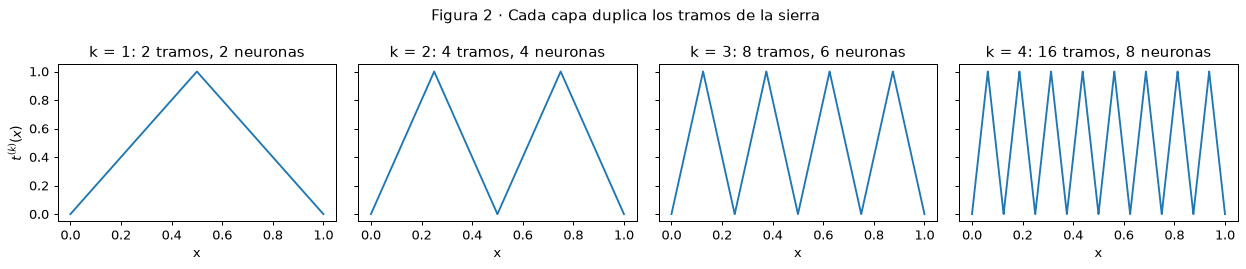

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, depth in zip(axes, range(1, 5), strict=True):
    y = forward(x_grid[:, None], sawtooth_layers(depth)).ravel()
    ax.plot(x_grid, y, color="tab:blue", linewidth=1.5)
    ax.set_title(f"k = {depth}: {2**depth} tramos, {2 * depth} neuronas")
    ax.set_xlabel("x")
axes[0].set_ylabel("$t^{(k)}(x)$")
fig.suptitle("Figura 2 · Cada capa duplica los tramos de la sierra")
fig.tight_layout()
plt.show()

### 3.3 La red poco profunda equivalente

Construimos a mano una red de **una** capa oculta que dibuja exactamente la misma sierra.
Usamos una neurona por tramo: la primera arranca la pendiente y cada una de las demás la
invierte en un quiebre (sección 2.5).

In [7]:
def shallow_sawtooth_layers(depth: int) -> list:
    """One-hidden-layer ReLU network with 2**depth neurons that draws the same sawtooth."""
    n_pieces = 2**depth
    starts = np.arange(n_pieces) / n_pieces  # where each neuron starts to act: 0, 1/2^k, ...
    slope = float(n_pieces)
    out_weights = np.empty(n_pieces)
    out_weights[0] = slope  # the first piece rises with slope 2^k
    # At every kink the slope flips sign: -2 * slope at odd kinks, +2 * slope at even ones.
    out_weights[1:] = np.where(np.arange(1, n_pieces) % 2 == 1, -2 * slope, 2 * slope)
    hidden = (np.ones((n_pieces, 1)), -starts, relu)
    output = (out_weights[None, :], np.array([0.0]), identity)
    return [hidden, output]


depth = 6
y_deep = forward(x_grid[:, None], sawtooth_layers(depth)).ravel()
y_shallow = forward(x_grid[:, None], shallow_sawtooth_layers(depth)).ravel()
print("same function:", np.allclose(y_deep, y_shallow))
print("max difference:", np.abs(y_deep - y_shallow).max())

same function: True
max difference: 0.0


### 3.4 La cuenta que lo dice todo

Comparamos, para cada número de capas $k$, las neuronas ocultas y los parámetros de las dos
redes que dibujan la misma sierra.

In [8]:
print(" k | pieces | deep neurons | shallow neurons | deep params | shallow params")
for depth in range(1, 11):
    deep_sizes = [1] + [2] * depth + [1]
    shallow_sizes = [1, 2**depth, 1]
    print(
        f"{depth:2d} | {2**depth:6d} | {2 * depth:12d} | {2**depth:15,d} | "
        f"{count_params(deep_sizes):11,d} | {count_params(shallow_sizes):14,d}"
    )

 k | pieces | deep neurons | shallow neurons | deep params | shallow params
 1 |      2 |            2 |               2 |           7 |              7
 2 |      4 |            4 |               4 |          13 |             13
 3 |      8 |            6 |               8 |          19 |             25
 4 |     16 |            8 |              16 |          25 |             49
 5 |     32 |           10 |              32 |          31 |             97
 6 |     64 |           12 |              64 |          37 |            193
 7 |    128 |           14 |             128 |          43 |            385
 8 |    256 |           16 |             256 |          49 |            769
 9 |    512 |           18 |             512 |          55 |          1,537
10 |   1024 |           20 |           1,024 |          61 |          3,073


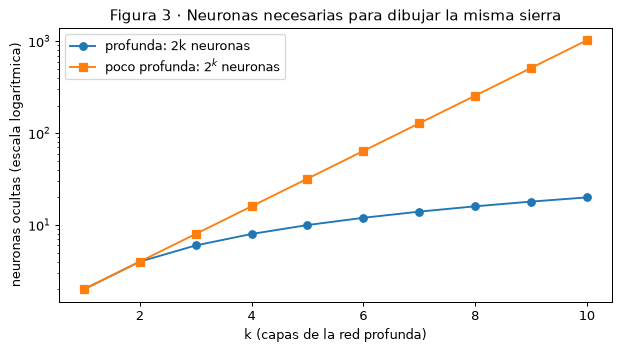

In [9]:
depths = np.arange(1, 11)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depths, 2 * depths, "o-", label="profunda: 2k neuronas")
ax.plot(depths, 2.0**depths, "s-", label="poco profunda: $2^k$ neuronas")
ax.set_yscale("log")
ax.set_xlabel("k (capas de la red profunda)")
ax.set_ylabel("neuronas ocultas (escala logarítmica)")
ax.set_title("Figura 3 · Neuronas necesarias para dibujar la misma sierra")
ax.legend()
fig.tight_layout()
plt.show()

## 4 · Con PyTorch

Escribimos un constructor general de redes, `make_mlp`, y cargamos en él los mismos pesos de
la red-sierra. Usamos `float64` (`.double()`) para que la comparación con NumPy sea exacta.

In [10]:
def make_mlp(sizes: list[int]) -> nn.Sequential:
    """Fully connected network with ReLU between layers and no activation at the output."""
    layers: list[nn.Module] = []
    for n_in, n_out in pairwise(sizes):
        layers += [nn.Linear(n_in, n_out), nn.ReLU()]
    return nn.Sequential(*layers[:-1])


depth = 6
model = make_mlp([1] + [2] * depth + [1]).double()
linears = [module for module in model if isinstance(module, nn.Linear)]

with torch.no_grad():
    for linear, (W, b, _) in zip(linears, sawtooth_layers(depth), strict=True):
        linear.weight.copy_(torch.from_numpy(W))
        linear.bias.copy_(torch.from_numpy(b))
    y_torch = model(torch.from_numpy(x_grid[:, None])).numpy().ravel()

print(model)
print("same as NumPy:", np.allclose(y_torch, y_deep))
print(
    "parameters:",
    sum(p.numel() for p in model.parameters()),
    "| by our formula:",
    count_params([1] + [2] * depth + [1]),
)

Sequential(
  (0): Linear(in_features=1, out_features=2, bias=True)
  (1): ReLU()
  (2): Linear(in_features=2, out_features=2, bias=True)
  (3): ReLU()
  (4): Linear(in_features=2, out_features=2, bias=True)
  (5): ReLU()
  (6): Linear(in_features=2, out_features=2, bias=True)
  (7): ReLU()
  (8): Linear(in_features=2, out_features=2, bias=True)
  (9): ReLU()
  (10): Linear(in_features=2, out_features=2, bias=True)
  (11): ReLU()
  (12): Linear(in_features=2, out_features=1, bias=True)
)
same as NumPy: True
parameters: 37 | by our formula: 37


## 5 · Experimenta

### Cambia la profundidad

Mueve el deslizador para cambiar $k$. Observa cómo la sierra se vuelve más fina y compara las
neuronas que necesita cada red. Los deslizadores funcionan al ejecutar el notebook; la
figura 2 muestra los primeros casos.

In [11]:
try:
    from ipywidgets import IntSlider, interact
except ImportError:  # pragma: no cover
    interact = None


def explore(depth: int = 3) -> None:
    """Plot the sawtooth of the given depth and compare the neurons each network needs."""
    y = forward(x_grid[:, None], sawtooth_layers(depth)).ravel()
    _, ax = plt.subplots(figsize=(7, 3))
    ax.plot(x_grid, y, color="tab:blue", linewidth=1)
    ax.set_title(
        f"k = {depth}: {2**depth} tramos · profunda: {2 * depth} neuronas · "
        f"poco profunda: {2**depth} neuronas"
    )
    ax.set_xlabel("x")
    plt.show()


if interact is not None:
    interact(explore, depth=IntSlider(value=3, min=1, max=8, step=1))

## 6 · Errores comunes

- **Pensar que más capas siempre es mejor.** Las redes muy profundas son más difíciles de
  entrenar (el gradiente puede desvanecerse, Tema 6) y pueden sobreajustar con más facilidad.
  La profundidad es una herramienta, no una garantía.
- **Leer el teorema de aproximación universal como "una capa basta en la práctica".** El
  teorema no dice cuántas neuronas hacen falta ni cómo encontrar los pesos.
- **Contar mal las capas.** Se cuentan las capas con pesos; la entrada no es una capa. Una
  red `[1, 2, 2, 1]` tiene 3 capas: 2 ocultas y 1 de salida.
- **Confundir profundidad con anchura.** Profundidad es el número de capas; anchura, el de
  neuronas por capa. Son decisiones distintas, con efectos distintos.
- **Olvidar la activación entre capas.** Sin ella, todas las capas colapsan en una sola
  (lección 1.2) y la sierra sería imposible.

## 7 · Ejercicios

**Ejercicio 1.** Diseña dos redes con casi el mismo número de parámetros (con una diferencia
menor al 10 %): una **ancha**, de una capa oculta, y otra **profunda**, de cuatro capas
ocultas, ambas con 10 entradas y 1 salida. Calcula sus parámetros con `count_params`.

In [12]:
# Ejercicio 1: tu código aquí


**Ejercicio 2.** Crea con NumPy los pesos aleatorios de una red 3 → 5 → 5 → 1 con ReLU en
las capas ocultas. Calcula su salida para 4 ejemplos con tu función `forward` y comprueba que
coincide con la de `make_mlp([3, 5, 5, 1])` cargada con los mismos pesos.

In [13]:
# Ejercicio 2: tu código aquí


**Ejercicio 3.** ¿Cuántos tramos tiene la sierra con $k = 6$? Predícelo con la fórmula de
la sección 2.4 y compruébalo con `count_linear_pieces`. ¿Cuántas neuronas necesitaría una red
de una sola capa?

In [14]:
# Ejercicio 3: tu código aquí


**Ejercicio 4.** Construye a mano una red de **una** capa oculta que dibuje en $[0, 1]$
una función con quiebres en $x = 0.25$, $0.5$ y $0.75$, que empiece en 0 con pendiente 1 y
cuya pendiente cambie a $-1$, $2$ y $0$ en cada quiebre. Dibújala para comprobarla.

In [15]:
# Ejercicio 4: tu código aquí


**Ejercicio 5.** Explica con tus palabras por qué la profundidad permite representar
funciones complejas con pocas neuronas, y qué cosas **no** garantiza agregar capas.

*Escribe aquí tu respuesta.*

## 8 · Para profundizar

- **Goodfellow, Bengio y Courville (2016), capítulo 6, sección 6.4:** diseño de arquitecturas,
  aproximación universal y profundidad.
- **Prince (2023), capítulo 4:** redes profundas y la idea de "doblar" el espacio de entrada.
- **Nielsen (2015), capítulo 4:** una prueba visual de que las redes pueden calcular cualquier
  función.

Artículos originales:
- Cybenko, G. (1989). Approximation by superpositions of a sigmoidal function. *Mathematics of Control, Signals and Systems*, 2(4), 303–314.
- Hornik, K., Stinchcombe, M. y White, H. (1989). Multilayer feedforward networks are universal approximators. *Neural Networks*, 2(5), 359–366.
- Montúfar, G., Pascanu, R., Cho, K. y Bengio, Y. (2014). On the number of linear regions of deep neural networks. *NeurIPS*.
- Telgarsky, M. (2016). Benefits of depth in neural networks. *COLT*. Es el origen de la construcción de la sierra; la implementación y las figuras de esta lección son propias.

Referencias completas en [SYLLABUS.md](../../SYLLABUS.md) y
[docs/REFERENCES.md](../../docs/REFERENCES.md).

---
*Texto y figuras: [CC BY 4.0](../../LICENSE-CONTENT). Código: [MIT](../../LICENSE).*